# TI3002C – Etapa 5.1: Código ML
**Equipo 6 – Nexxus Consulting**
**Nombre:** Jaime Hernández González
**Matrícula:** A00840312

**Problemática (regresión):** pronosticar las **unidades vendidas (`units_sold`)** de cada producto, en cada región y en cada mes, para que DanuStore planee su inventario con un pronóstico más preciso que el que usa hoy (`units_expected`).

**Modelos:** Random Forest y XGBoost (los dos propuestos en la investigación de la Etapa 5.1).

## 1. Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_colwidth', None)   # para ver los hiperparámetros completos en las tablas

## 2. Importar datos
Se usa la base **mensual (Nivel Macro)**: 130 productos × 7 regiones × 24 meses (2024–2025).

In [2]:
# Si usas Google Drive, monta tu Drive y cambia la ruta:
# from google.colab import drive
# drive.mount('/content/drive')
# df = pd.read_csv('/content/drive/MyDrive/data_DanuStore_Equipo6_Mensual.csv')

df = pd.read_csv('data_DanuStore_Equipo6_Mensual.csv')
print(df.shape)
df.head()

(21840, 20)


,month,year,product_id,region,units_expected,stock,percentage,units_sold,sales_amount,product_name,category,subcategory,static_price,inventory_key,Ventas_Acumuladas_Mensual,Stock_Restante_Mensual,Cumplimiento_Venta_Esperada,Product_Repeat_Purchase_Rate,Venta_Promedio_Diaria,Dias_Cobertura_Inventario
0,March,2025,39,Bajío,1057,1735,164.14,107,4045.32,Shirts Product 39,Casual Wear,Shirts,45.40,Bajío_39_March_2025,107,1628,10.12,99.92,3.451613,502.66
1,October,2025,46,Ciudad de México,1983,3215,162.13,671,49978.14,Pants Product 46,Casual Wear,Pants,87.10,Ciudad de México_46_October_2025,671,2544,33.84,99.89,21.645161,148.53
2,May,2025,113,Ciudad de México,2549,4030,158.10,693,52325.53,Boots Product 113,Footwear,Boots,88.06,Ciudad de México_113_May_2025,693,3337,27.19,99.88,22.354839,180.27
3,February,2025,75,Ciudad de México,1388,2192,157.93,355,23911.75,Jewelry Product 75,Accessories,Jewelry,79.43,Ciudad de México_75_February_2025,355,1837,25.58,99.84,12.678571,172.89
4,October,2025,84,Ciudad de México,1458,2298,157.61,467,18204.74,Hats Product 84,Accessories,Hats,44.88,Ciudad de México_84_October_2025,467,1831,32.03,99.78,15.064516,152.54


### 2.0 Exploración inicial
Revisamos el tamaño de la base, los tipos de datos, si hay valores nulos o registros duplicados, y las estadísticas básicas de la variable objetivo.

In [3]:
print('Filas y columnas:', df.shape)
print('Valores nulos en toda la base:', df.isnull().sum().sum())
print('Registros duplicados:', df.duplicated().sum())
print('Productos:', df['product_id'].nunique(), '| Regiones:', df['region'].nunique(), '| Categorías:', df['category'].nunique())
df.dtypes

Filas y columnas: (21840, 20)
Valores nulos en toda la base: 0
Registros duplicados: 0
Productos: 130 | Regiones: 7 | Categorías: 4


month                               str
year                              int64
product_id                        int64
region                              str
units_expected                    int64
stock                             int64
percentage                      float64
units_sold                        int64
sales_amount                    float64
product_name                        str
category                            str
subcategory                         str
static_price                    float64
inventory_key                       str
Ventas_Acumuladas_Mensual         int64
Stock_Restante_Mensual            int64
Cumplimiento_Venta_Esperada     float64
Product_Repeat_Purchase_Rate    float64
Venta_Promedio_Diaria           float64
Dias_Cobertura_Inventario       float64
dtype: object

In [4]:
df[['units_sold', 'units_expected', 'stock', 'static_price']].describe().round(2)

,units_sold,units_expected,stock,static_price
count,21840.00,21840.00,21840.00,21840.00
mean,207.55,1222.49,1358.55,83.64
std,175.59,434.38,566.11,44.36
min,15.00,323.00,120.00,21.99
25%,81.00,888.75,930.00,48.67
50%,138.50,1192.00,1279.00,77.18
75%,286.00,1507.00,1703.00,104.50
max,1240.00,3111.00,4732.00,231.68


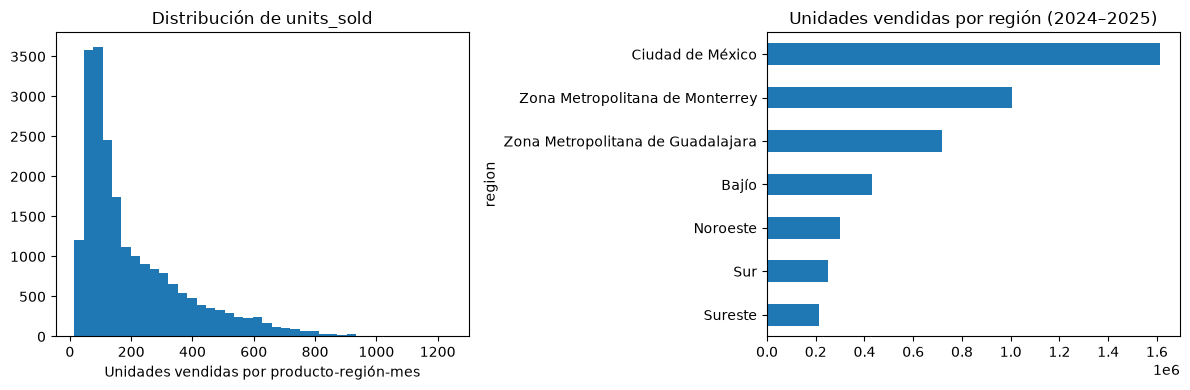

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(df['units_sold'], bins=40)
ax[0].set_title('Distribución de units_sold')
ax[0].set_xlabel('Unidades vendidas por producto-región-mes')

df.groupby('region')['units_sold'].sum().sort_values().plot(kind='barh', ax=ax[1])
ax[1].set_title('Unidades vendidas por región (2024–2025)')
plt.tight_layout()
plt.show()

**Interpretación:** la base no tiene nulos ni duplicados. `units_sold` tiene sesgo a la derecha (la mayoría de los registros vende poco y pocos venden mucho) y las ventas se concentran en CDMX, Monterrey y Guadalajara, por lo que la **región** será una variable importante.

### 2.1 Preparar la fecha
La columna `month` viene como texto (January, February…). La convertimos a número y creamos una fecha para poder ordenar los datos en el tiempo.

In [6]:
meses = {'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
         'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12}

df['mes'] = df['month'].map(meses)
df['fecha'] = pd.to_datetime(dict(year=df['year'], month=df['mes'], day=1))

# Ordenar por producto, región y fecha
df = df.sort_values(['product_id', 'region', 'fecha']).reset_index(drop=True)
df[['product_id', 'region', 'fecha', 'units_sold', 'units_expected']].head()

,product_id,region,fecha,units_sold,units_expected
0,1,Bajío,2024-01-01,136,1398
1,1,Bajío,2024-02-01,161,1456
2,1,Bajío,2024-03-01,148,1363
3,1,Bajío,2024-04-01,161,1283
4,1,Bajío,2024-05-01,177,1367


### 2.2 Las ventas a través del tiempo
Antes de modelar vemos cómo se comportan las ventas reales contra lo que DanuStore esperaba vender.

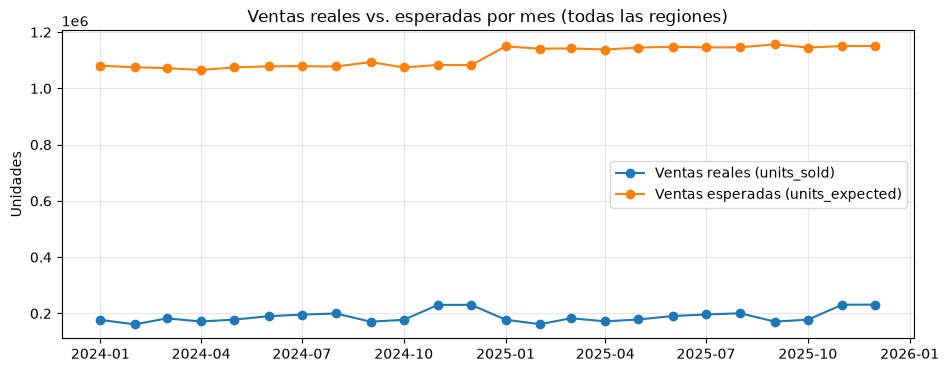

Se vendió el 17.0 % de lo esperado


In [7]:
por_mes = df.groupby('fecha')[['units_sold', 'units_expected']].sum()

plt.figure(figsize=(11, 4))
plt.plot(por_mes.index, por_mes['units_sold'], marker='o', label='Ventas reales (units_sold)')
plt.plot(por_mes.index, por_mes['units_expected'], marker='o', label='Ventas esperadas (units_expected)')
plt.title('Ventas reales vs. esperadas por mes (todas las regiones)')
plt.ylabel('Unidades')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('Se vendió el', round(por_mes['units_sold'].sum() / por_mes['units_expected'].sum() * 100, 1), '% de lo esperado')

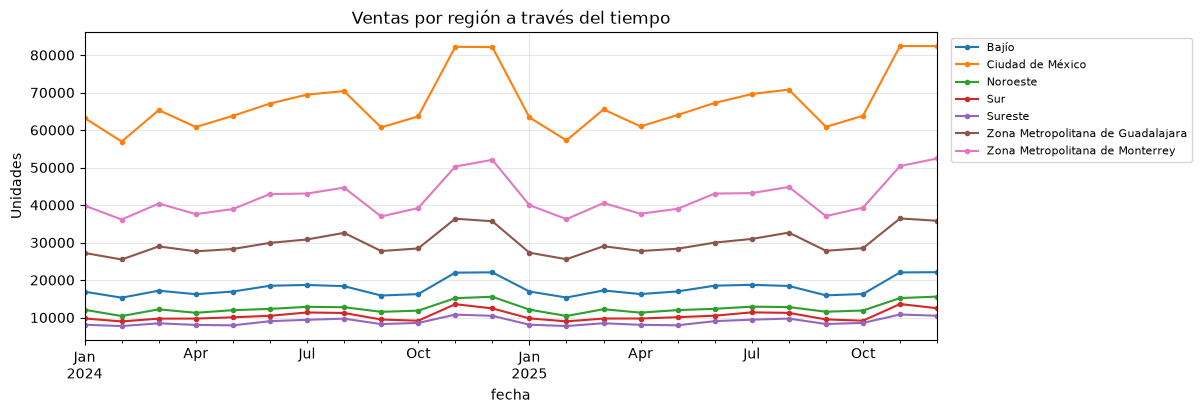

In [8]:
# Tabla con una fila por mes y una columna por región
por_region_mes = df.pivot_table(index='fecha', columns='region', values='units_sold', aggfunc='sum')

por_region_mes.plot(figsize=(11, 4), marker='.')
plt.title('Ventas por región a través del tiempo')
plt.ylabel('Unidades')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.grid(alpha=0.3)
plt.show()

**Interpretación:** el pronóstico actual (`units_expected`) es casi plano y muy superior a las ventas reales, mientras que las ventas sí tienen picos (noviembre y diciembre) en todas las regiones, y el patrón de 2025 es igual al de 2024. Esto confirma que hace falta un modelo que aprenda el comportamiento real de las ventas.

## 3. Selección de variables
### 3.1 Universo de variables
- **Variable objetivo (y):** `units_sold`.
- **Variables candidatas:** `region`, `category`, `subcategory`, `mes`, `static_price` y las **ventas de meses anteriores** (rezagos), que creamos a continuación.

Para pronosticar el mes siguiente solo podemos usar información que **ya conocemos**. Por eso creamos:
- `ventas_mes_anterior`: ventas del mes pasado (t−1).
- `ventas_hace_2` y `ventas_hace_3`: ventas de hace 2 y 3 meses.
- `promedio_3_meses`: promedio de los 3 meses anteriores.

In [9]:
# Agrupamos por producto y región para que cada serie use SUS propias ventas pasadas
grupo = df.groupby(['product_id', 'region'])['units_sold']

df['ventas_mes_anterior'] = grupo.shift(1)
df['ventas_hace_2'] = grupo.shift(2)
df['ventas_hace_3'] = grupo.shift(3)
df['promedio_3_meses'] = (df['ventas_mes_anterior'] + df['ventas_hace_2'] + df['ventas_hace_3']) / 3
df['ventas_hace_12'] = grupo.shift(12)   # mismo mes del año pasado (solo para revisarla)

df[['product_id', 'region', 'fecha', 'units_sold', 'ventas_mes_anterior', 'promedio_3_meses']].head(6)

,product_id,region,fecha,units_sold,ventas_mes_anterior,promedio_3_meses
0,1,Bajío,2024-01-01,136,NaN,NaN
1,1,Bajío,2024-02-01,161,136.0,NaN
2,1,Bajío,2024-03-01,148,161.0,NaN
3,1,Bajío,2024-04-01,161,148.0,148.333333
4,1,Bajío,2024-05-01,177,161.0,156.666667
5,1,Bajío,2024-06-01,136,177.0,162.000000


### 3.2 Variables que NO se pueden usar
Estas variables se calculan **con las ventas del mismo mes** que queremos pronosticar. Si las usamos, el modelo "haría trampa" (fuga de información) porque en la vida real no las conocemos antes de que termine el mes:

| Variable | Por qué se excluye |
|---|---|
| `Ventas_Acumuladas_Mensual` | Es igual a `units_sold` |
| `Venta_Promedio_Diaria` | Es `units_sold` ÷ días del mes |
| `sales_amount` | Es `units_sold` × precio |
| `Cumplimiento_Venta_Esperada` | Es `units_sold` ÷ `units_expected` |
| `Dias_Cobertura_Inventario` | Usa la venta promedio diaria |
| `Stock_Restante_Mensual` | Es stock − `units_sold` |

`units_expected` tampoco se usa como variable: se usa como **punto de comparación** (es el pronóstico actual de la empresa).

### 3.3 Correlaciones más importantes

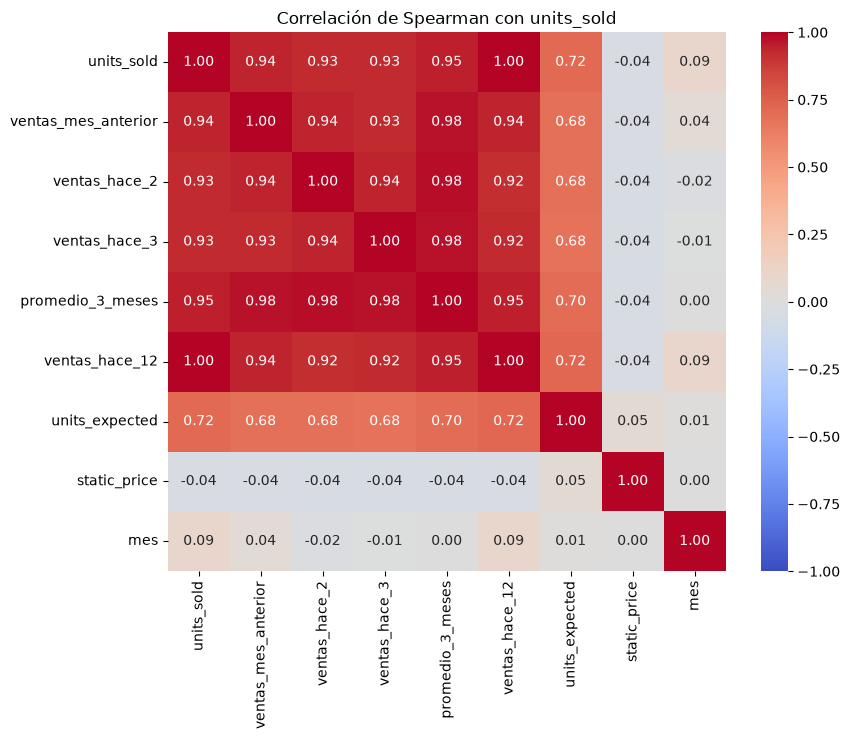

units_sold             1.000
ventas_hace_12         1.000
promedio_3_meses       0.950
ventas_mes_anterior    0.939
ventas_hace_3          0.927
ventas_hace_2          0.927
units_expected         0.715
mes                    0.093
static_price          -0.038
Name: units_sold, dtype: float64


In [10]:
variables_numericas = ['units_sold', 'ventas_mes_anterior', 'ventas_hace_2', 'ventas_hace_3',
                       'promedio_3_meses', 'ventas_hace_12', 'units_expected', 'static_price', 'mes']

correlacion = df[variables_numericas].corr(method='spearman')

plt.figure(figsize=(9, 7))
sns.heatmap(correlacion, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación de Spearman con units_sold')
plt.show()

print(correlacion['units_sold'].sort_values(ascending=False).round(3))

In [11]:
# ¿Las ventas de 2025 se parecen a las de 2024?
tabla = df.pivot_table(index=['product_id', 'region', 'mes'], columns='year', values='units_sold')
iguales = (tabla[2024] == tabla[2025]).mean() * 100
print('Registros donde las ventas de 2025 son IGUALES a las de 2024:', round(iguales, 1), '%')
print('Diferencia promedio entre 2025 y 2024:', round((tabla[2025] - tabla[2024]).abs().mean(), 2), 'unidades')

Registros donde las ventas de 2025 son IGUALES a las de 2024: 76.6 %
Diferencia promedio entre 2025 y 2024: 0.61 unidades


**Interpretación y selección:**
- Las ventas de los meses anteriores (`ventas_mes_anterior`, `promedio_3_meses`) son las variables más relacionadas con `units_sold`, por eso se seleccionan.
- `units_expected` tiene una correlación menor: ordena bien qué productos venden más, pero no acierta en la cantidad.
- `mes` tiene correlación baja por sí sola, pero se conserva porque los árboles pueden encontrar **combinaciones** (por ejemplo, región × mes, o la temporada de noviembre–diciembre) que una correlación no detecta.
- **`static_price` NO se usa:** cada producto tiene un precio único (ver la celda siguiente), así que el precio funciona como un **identificador del producto**. Como las ventas de 2025 repiten las de 2024, el modelo lo usaría para "recordar" cuánto vendió cada producto en lugar de aprender patrones, y podría depender de que los precios no cambien. Se excluye como **decisión experimental** para reducir esa dependencia; en la sección 12 se comprueba que quitarlo casi no cambia el error.
- **`ventas_hace_12` NO se usa como variable del modelo:** su correlación es prácticamente 1 porque en la base **las ventas de 2025 repiten casi exactamente las de 2024**. Se excluye como **decisión experimental** para evaluar modelos basados en información reciente; su efecto sobre la generalización queda pendiente de validar. Además, solo existe para 2025, lo que dejaría muy pocos meses para entrenar. **Sí se usa como línea base** ("vender lo mismo que hace un año", sección 7.1), porque esa información está disponible al pronosticar. Este hallazgo se reportará al socio formador como una observación sobre la calidad de los datos.

**Variables seleccionadas:** `region`, `category`, `subcategory`, `mes`, `ventas_mes_anterior`, `ventas_hace_2`, `ventas_hace_3`, `promedio_3_meses`.

In [12]:
# ¿El precio identifica al producto?
print('Productos distintos:', df['product_id'].nunique())
print('Precios distintos:', df['static_price'].nunique())
print('¿Cada producto tiene un solo precio?', (df.groupby('product_id')['static_price'].nunique() == 1).all())

Productos distintos: 130
Precios distintos: 130
¿Cada producto tiene un solo precio? True


## 4. Codificar variables categóricas
Los modelos solo entienden números. `region`, `category` y `subcategory` son texto, así que se convierten con **One-Hot Encoding** (`pd.get_dummies`): se crea una columna de 0 y 1 por cada categoría.

In [13]:
# Quitamos los 3 primeros meses de cada serie (no tienen ventas anteriores para calcular los rezagos)
datos = df.dropna(subset=['promedio_3_meses']).copy()

variables = ['region', 'category', 'subcategory', 'mes',
             'ventas_mes_anterior', 'ventas_hace_2', 'ventas_hace_3', 'promedio_3_meses']

X = pd.get_dummies(datos[variables], columns=['region', 'category', 'subcategory'], dtype=int)
y = datos['units_sold']

print('Registros:', X.shape[0], '| Columnas después de codificar:', X.shape[1])
X.head()

Registros: 19110 | Columnas después de codificar: 29


,mes,ventas_mes_anterior,ventas_hace_2,ventas_hace_3,promedio_3_meses,region_Bajío,region_Ciudad de México,region_Noroeste,region_Sur,region_Sureste,...,subcategory_Bottoms,subcategory_Dresses,subcategory_Hats,subcategory_Jewelry,subcategory_Outerwear,subcategory_Pants,subcategory_Sandals,subcategory_Shirts,subcategory_Sneakers,subcategory_Tops
3,4,148.0,161.0,136.0,148.333333,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,5,161.0,148.0,161.0,156.666667,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
5,6,177.0,161.0,148.0,162.000000,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
6,7,136.0,177.0,161.0,158.000000,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
7,8,143.0,136.0,177.0,152.000000,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


## 5. Normalización / estandarización
**No es necesaria.** Random Forest y XGBoost son modelos de **árboles de decisión**: separan los datos con reglas del tipo "¿ventas del mes anterior > 150?". Esas reglas funcionan igual si la variable está en unidades, en miles o estandarizada, así que la escala no cambia el resultado. La normalización sí sería necesaria en modelos que comparan distancias o usan coeficientes, como KNN, regresión lineal regularizada (Ridge/Lasso) o redes neuronales.

## 6. Partición de los datos (temporal)
Como queremos pronosticar el **futuro**, no se usa una partición aleatoria: se entrena con los meses más antiguos y se prueba con los más recientes. Se prueban **tres particiones** (los datos con rezagos van de abril 2024 a diciembre 2025, 21 meses):
- **80/20:** entrenar hasta agosto 2025 (17 meses) y probar con septiembre–diciembre 2025 (4 meses).
- **70/30:** entrenar hasta junio 2025 (15 meses) y probar con julio–diciembre 2025 (6 meses).
- **60/40:** entrenar hasta abril 2025 (13 meses) y probar con mayo–diciembre 2025 (8 meses).

**Importante:** en las secciones 7 a 12 la evaluación es **a un mes**: para pronosticar cada mes de prueba se usan las ventas **reales** del mes anterior, como pasaría si DanuStore pronostica cada mes cuando ya cerró el anterior. El pronóstico de varios meses desde un solo punto, sin conocer las ventas intermedias, se evalúa en la sección 13.

Las tres particiones tienen **periodos de prueba distintos y que se enciman** (septiembre–diciembre, julio–diciembre y mayo–diciembre), así que sus errores no se pueden comparar directamente para decir que una es "mejor": las diferencias pueden deberse a los meses que se evalúan (por ejemplo, la temporada de noviembre–diciembre). Sirven para ver si el modelo es **estable** con distintas cantidades de datos.

In [14]:
particiones = {
    '80/20': '2025-09-01',
    '70/30': '2025-07-01',
    '60/40': '2025-05-01',
}

for nombre, corte in particiones.items():
    entrenamiento = datos['fecha'] < corte
    print(nombre, '-> entrenamiento:', entrenamiento.sum(), 'registros | prueba:', (~entrenamiento).sum(), 'registros')

80/20 -> entrenamiento: 15470 registros | prueba: 3640 registros
70/30 -> entrenamiento: 13650 registros | prueba: 5460 registros
60/40 -> entrenamiento: 11830 registros | prueba: 7280 registros


## 7. Métricas de evaluación
- **MAE:** error promedio en unidades.
- **RMSE:** como el MAE, pero castiga más los errores grandes.
- **WAPE:** error total ÷ ventas totales (en %). Es la métrica principal porque se lee fácil: "el pronóstico se equivoca X% de lo que se vende".
- **R²:** qué tanto de la variación de las ventas explica el modelo (1 = perfecto).

In [15]:
def evaluar(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    wape = np.abs(y_real - y_pred).sum() / y_real.sum() * 100
    r2 = r2_score(y_real, y_pred)
    # float() convierte los resultados a números normales de Python para que se impriman limpios
    return {'MAE': round(float(mae), 2), 'RMSE': round(float(rmse), 2), 'WAPE (%)': round(float(wape), 2), 'R2': round(float(r2), 3)}

### 7.1 Puntos de comparación (líneas base)
Un modelo solo sirve si le gana a lo que ya existe:
1. **Pronóstico actual de DanuStore** (`units_expected`).
2. **Modelo ingenuo:** "este mes voy a vender lo mismo que el mes pasado".
3. **Ingenuo estacional:** "este mes voy a vender lo mismo que en el mismo mes del año pasado".

In [16]:
resultados = []

for nombre, corte in particiones.items():
    prueba = datos['fecha'] >= corte
    fila = evaluar(y[prueba], datos.loc[prueba, 'units_expected'])
    fila['Modelo'] = 'Pronóstico actual (units_expected)'
    fila['Partición'] = nombre
    fila['Hiperparámetros'] = '-'
    resultados.append(fila)

    fila = evaluar(y[prueba], datos.loc[prueba, 'ventas_mes_anterior'])
    fila['Modelo'] = 'Ingenuo (mes anterior)'
    fila['Partición'] = nombre
    fila['Hiperparámetros'] = '-'
    resultados.append(fila)

    fila = evaluar(y[prueba], datos.loc[prueba, 'ventas_hace_12'])
    fila['Modelo'] = 'Ingenuo estacional (mismo mes del año anterior)'
    fila['Partición'] = nombre
    fila['Hiperparámetros'] = '-'
    resultados.append(fila)

pd.DataFrame(resultados)[['Partición', 'Modelo', 'Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

,Partición,Modelo,Hiperparámetros,MAE,RMSE,WAPE (%),R2
0,80/20,Pronóstico actual (units_expected),-,1042.04,1093.44,467.95,-32.190
1,80/20,Ingenuo (mes anterior),-,44.15,66.71,19.83,0.876
2,80/20,Ingenuo estacional (mismo mes del año anterior),-,0.64,4.12,0.29,1.000
3,70/30,Pronóstico actual (units_expected),-,1041.87,1093.51,471.23,-33.236
4,70/30,Ingenuo (mes anterior),-,41.23,62.18,18.65,0.889
5,70/30,Ingenuo estacional (mismo mes del año anterior),-,0.68,4.43,0.31,0.999
6,60/40,Pronóstico actual (units_expected),-,1045.73,1097.63,483.00,-35.065
7,60/40,Ingenuo (mes anterior),-,39.34,59.34,18.17,0.895
8,60/40,Ingenuo estacional (mismo mes del año anterior),-,0.64,4.04,0.30,1.000


**Interpretación de las líneas base:**
- El pronóstico actual de DanuStore se equivoca ~470 %, y repetir el mes pasado ~19 %.
- **Repetir el mismo mes del año pasado se equivoca menos del 0.5 %.** Esto no es porque sea un buen método en general, sino porque **en esta base las ventas de 2025 son casi una copia de las de 2024** (sección 3.3). Es el método con menor error entre los evaluados, y esta repetición es la principal limitante del análisis: se reportará al socio formador.
- Los modelos de ML se construyen **sin** las ventas del año anterior como decisión experimental: así dependen del nivel de ventas reciente, la región y la temporada, y no de copiar el año anterior. Si esto realmente funciona mejor cuando las ventas no se repiten es algo que **queda pendiente de validar** con datos nuevos.

## 8. Modelo 1: Random Forest
Entrena muchos árboles de decisión, cada uno con una muestra aleatoria de los datos, y **promedia** sus pronósticos.

Hiperparámetros que se prueban (3 configuraciones):
- `n_estimators`: número de árboles.
- `max_depth`: profundidad máxima de cada árbol (None = sin límite).
- `min_samples_leaf`: mínimo de registros en cada hoja (evita que el árbol memorice).

In [17]:
# Las 3 configuraciones de Random Forest: el texto es el nombre y a la derecha está el modelo
opciones_rf = {
    'n_estimators=100, max_depth=None, min_samples_leaf=1': RandomForestRegressor(n_estimators=100, max_depth=None, min_samples_leaf=1, random_state=42),
    'n_estimators=200, max_depth=15, min_samples_leaf=2':   RandomForestRegressor(n_estimators=200, max_depth=15, min_samples_leaf=2, random_state=42),
    'n_estimators=300, max_depth=8, min_samples_leaf=5':    RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5, random_state=42),
}

for nombre, corte in particiones.items():
    entrenamiento = datos['fecha'] < corte
    prueba = datos['fecha'] >= corte

    for hiperparametros, modelo in opciones_rf.items():
        modelo.fit(X[entrenamiento], y[entrenamiento])     # entrenar
        prediccion = modelo.predict(X[prueba])               # pronosticar

        fila = evaluar(y[prueba], prediccion)                # calcular las métricas
        fila['Modelo'] = 'Random Forest'
        fila['Partición'] = nombre
        fila['Hiperparámetros'] = hiperparametros
        resultados.append(fila)

tabla = pd.DataFrame(resultados)
tabla[tabla['Modelo'] == 'Random Forest'][['Partición', 'Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

,Partición,Hiperparámetros,MAE,RMSE,WAPE (%),R2
9,80/20,"n_estimators=100, max_depth=None, min_samples_leaf=1",13.31,20.80,5.98,0.988
10,80/20,"n_estimators=200, max_depth=15, min_samples_leaf=2",16.57,25.07,7.44,0.983
11,80/20,"n_estimators=300, max_depth=8, min_samples_leaf=5",26.93,38.72,12.10,0.958
12,70/30,"n_estimators=100, max_depth=None, min_samples_leaf=1",13.42,20.92,6.07,0.987
13,70/30,"n_estimators=200, max_depth=15, min_samples_leaf=2",17.55,26.18,7.94,0.980
14,70/30,"n_estimators=300, max_depth=8, min_samples_leaf=5",27.25,39.35,12.33,0.956
15,60/40,"n_estimators=100, max_depth=None, min_samples_leaf=1",13.26,20.76,6.12,0.987
16,60/40,"n_estimators=200, max_depth=15, min_samples_leaf=2",17.52,25.93,8.09,0.980
17,60/40,"n_estimators=300, max_depth=8, min_samples_leaf=5",27.08,39.15,12.51,0.954


## 9. Modelo 2: XGBoost
Construye árboles **uno tras otro**; cada árbol nuevo corrige los errores de los anteriores.

Hiperparámetros que se prueban (3 configuraciones):
- `n_estimators`: número de árboles.
- `learning_rate`: qué tanto corrige cada árbol (más bajo = más lento pero más cuidadoso).
- `max_depth`: profundidad máxima de cada árbol.

In [18]:
opciones_xgb = {
    'n_estimators=300, learning_rate=0.1, max_depth=6':  XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42),
    'n_estimators=500, learning_rate=0.05, max_depth=4': XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, random_state=42),
    'n_estimators=800, learning_rate=0.03, max_depth=8': XGBRegressor(n_estimators=800, learning_rate=0.03, max_depth=8, random_state=42),
}

for nombre, corte in particiones.items():
    entrenamiento = datos['fecha'] < corte
    prueba = datos['fecha'] >= corte

    for hiperparametros, modelo in opciones_xgb.items():
        modelo.fit(X[entrenamiento], y[entrenamiento])
        prediccion = modelo.predict(X[prueba])

        fila = evaluar(y[prueba], prediccion)
        fila['Modelo'] = 'XGBoost'
        fila['Partición'] = nombre
        fila['Hiperparámetros'] = hiperparametros
        resultados.append(fila)

tabla = pd.DataFrame(resultados)
tabla[tabla['Modelo'] == 'XGBoost'][['Partición', 'Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

,Partición,Hiperparámetros,MAE,RMSE,WAPE (%),R2
18,80/20,"n_estimators=300, learning_rate=0.1, max_depth=6",20.23,27.61,9.09,0.979
19,80/20,"n_estimators=500, learning_rate=0.05, max_depth=4",26.26,37.27,11.79,0.961
20,80/20,"n_estimators=800, learning_rate=0.03, max_depth=8",14.64,20.54,6.58,0.988
21,70/30,"n_estimators=300, learning_rate=0.1, max_depth=6",20.60,28.31,9.32,0.977
22,70/30,"n_estimators=500, learning_rate=0.05, max_depth=4",26.51,37.87,11.99,0.959
23,70/30,"n_estimators=800, learning_rate=0.03, max_depth=8",15.42,21.84,6.97,0.986
24,60/40,"n_estimators=300, learning_rate=0.1, max_depth=6",20.35,27.86,9.40,0.977
25,60/40,"n_estimators=500, learning_rate=0.05, max_depth=4",25.97,36.91,11.99,0.959
26,60/40,"n_estimators=800, learning_rate=0.03, max_depth=8",15.26,21.12,7.05,0.987


## 10. Comparación de todos los modelos

In [19]:
tabla_final = pd.DataFrame(resultados)[['Partición', 'Modelo', 'Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]
tabla_final = tabla_final.sort_values(['Partición', 'WAPE (%)'])
tabla_final

,Partición,Modelo,Hiperparámetros,MAE,RMSE,WAPE (%),R2
8,60/40,Ingenuo estacional (mismo mes del año anterior),-,0.64,4.04,0.30,1.000
15,60/40,Random Forest,"n_estimators=100, max_depth=None, min_samples_leaf=1",13.26,20.76,6.12,0.987
26,60/40,XGBoost,"n_estimators=800, learning_rate=0.03, max_depth=8",15.26,21.12,7.05,0.987
16,60/40,Random Forest,"n_estimators=200, max_depth=15, min_samples_leaf=2",17.52,25.93,8.09,0.980
24,60/40,XGBoost,"n_estimators=300, learning_rate=0.1, max_depth=6",20.35,27.86,9.40,0.977
25,60/40,XGBoost,"n_estimators=500, learning_rate=0.05, max_depth=4",25.97,36.91,11.99,0.959
17,60/40,Random Forest,"n_estimators=300, max_depth=8, min_samples_leaf=5",27.08,39.15,12.51,0.954
7,60/40,Ingenuo (mes anterior),-,39.34,59.34,18.17,0.895
6,60/40,Pronóstico actual (units_expected),-,1045.73,1097.63,483.00,-35.065
5,70/30,Ingenuo estacional (mismo mes del año anterior),-,0.68,4.43,0.31,0.999


In [20]:
# Tabla resumen: el menor WAPE (%) de cada modelo en cada partición
resumen = tabla_final.pivot_table(index='Modelo', columns='Partición', values='WAPE (%)', aggfunc='min')
resumen = resumen[['80/20', '70/30', '60/40']].sort_values('80/20')
resumen

Partición,80/20,70/30,60/40
Modelo,,,
Ingenuo estacional (mismo mes del año anterior),0.29,0.31,0.30
Random Forest,5.98,6.07,6.12
XGBoost,6.58,6.97,7.05
Ingenuo (mes anterior),19.83,18.65,18.17
Pronóstico actual (units_expected),467.95,471.23,483.00


In [21]:
# Mejor configuración de cada modelo en la partición 80/20
# (se ordena por WAPE y se deja solo la primera fila de cada modelo)
mejores = tabla_final[tabla_final['Partición'] == '80/20'].sort_values('WAPE (%)')
mejores = mejores.drop_duplicates(subset='Modelo')
mejores[['Modelo', 'Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

,Modelo,Hiperparámetros,MAE,RMSE,WAPE (%),R2
2,Ingenuo estacional (mismo mes del año anterior),-,0.64,4.12,0.29,1.000
9,Random Forest,"n_estimators=100, max_depth=None, min_samples_leaf=1",13.31,20.80,5.98,0.988
20,XGBoost,"n_estimators=800, learning_rate=0.03, max_depth=8",14.64,20.54,6.58,0.988
1,Ingenuo (mes anterior),-,44.15,66.71,19.83,0.876
0,Pronóstico actual (units_expected),-,1042.04,1093.44,467.95,-32.190


### 10.1 Comprobación de los hiperparámetros con validación temporal
En las tablas anteriores (análisis exploratorio) se vio el error de todas las configuraciones en los meses de prueba, así que elegir la mejor con esas tablas da un resultado **optimista**. Para comprobar la elección sin depender de esos meses:
1. Dentro del periodo de entrenamiento se separa una **validación**: se entrena hasta abril 2025 y se evalúa con mayo–agosto 2025.
2. Se elige **automáticamente** la configuración con menor error en validación para cada modelo.
3. Esas configuraciones son las que se usan en las secciones 11 a 13.

In [22]:
entrenamiento_val = datos['fecha'] < '2025-05-01'
validacion = (datos['fecha'] >= '2025-05-01') & (datos['fecha'] < '2025-09-01')

tabla_validacion = []

for hiperparametros, modelo in opciones_rf.items():
    modelo.fit(X[entrenamiento_val], y[entrenamiento_val])
    fila = evaluar(y[validacion], modelo.predict(X[validacion]))
    fila['Modelo'] = 'Random Forest'
    fila['Hiperparámetros'] = hiperparametros
    tabla_validacion.append(fila)

for hiperparametros, modelo in opciones_xgb.items():
    modelo.fit(X[entrenamiento_val], y[entrenamiento_val])
    fila = evaluar(y[validacion], modelo.predict(X[validacion]))
    fila['Modelo'] = 'XGBoost'
    fila['Hiperparámetros'] = hiperparametros
    tabla_validacion.append(fila)

tabla_validacion = pd.DataFrame(tabla_validacion).sort_values('WAPE (%)')

# La mejor configuración de cada modelo es la de menor WAPE en validación
mejor_hiper_rf = tabla_validacion[tabla_validacion['Modelo'] == 'Random Forest']['Hiperparámetros'].iloc[0]
mejor_hiper_xgb = tabla_validacion[tabla_validacion['Modelo'] == 'XGBoost']['Hiperparámetros'].iloc[0]
print('Configuración elegida para Random Forest:', mejor_hiper_rf)
print('Configuración elegida para XGBoost:', mejor_hiper_xgb)

print('Error en VALIDACIÓN (mayo–agosto 2025):')
tabla_validacion[['Modelo', 'Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

Configuración elegida para Random Forest: n_estimators=100, max_depth=None, min_samples_leaf=1
Configuración elegida para XGBoost: n_estimators=800, learning_rate=0.03, max_depth=8
Error en VALIDACIÓN (mayo–agosto 2025):


,Modelo,Hiperparámetros,MAE,RMSE,WAPE (%),R2
0,Random Forest,"n_estimators=100, max_depth=None, min_samples_leaf=1",13.20,20.67,6.28,0.986
5,XGBoost,"n_estimators=800, learning_rate=0.03, max_depth=8",16.64,22.91,7.91,0.983
1,Random Forest,"n_estimators=200, max_depth=15, min_samples_leaf=2",18.59,26.92,8.84,0.976
3,XGBoost,"n_estimators=300, learning_rate=0.1, max_depth=6",21.08,28.98,10.02,0.973
4,XGBoost,"n_estimators=500, learning_rate=0.05, max_depth=4",25.94,37.02,12.33,0.955
2,Random Forest,"n_estimators=300, max_depth=8, min_samples_leaf=5",27.72,40.27,13.18,0.947


**Resultado:** la validación temporal eligió **Random Forest con 100 árboles sin límite de profundidad** y **XGBoost con 800 árboles, `learning_rate` = 0.03 y `max_depth` = 8**, las mismas configuraciones identificadas en el análisis exploratorio. Como los meses de prueba (septiembre–diciembre 2025) ya se habían consultado en las secciones 8–10, **falta una evaluación independiente con datos nuevos**.

## 11. Resultados de los mejores modelos
Se entrenan las configuraciones elegidas en validación con todos los datos hasta agosto 2025 y se evalúan en septiembre–diciembre 2025 (partición 80/20) para visualizar sus resultados.

Resultado en la prueba (septiembre–diciembre 2025):
Random Forest: {'MAE': 13.31, 'RMSE': 20.8, 'WAPE (%)': 5.98, 'R2': 0.988}
XGBoost:       {'MAE': 14.64, 'RMSE': 20.54, 'WAPE (%)': 6.58, 'R2': 0.988}


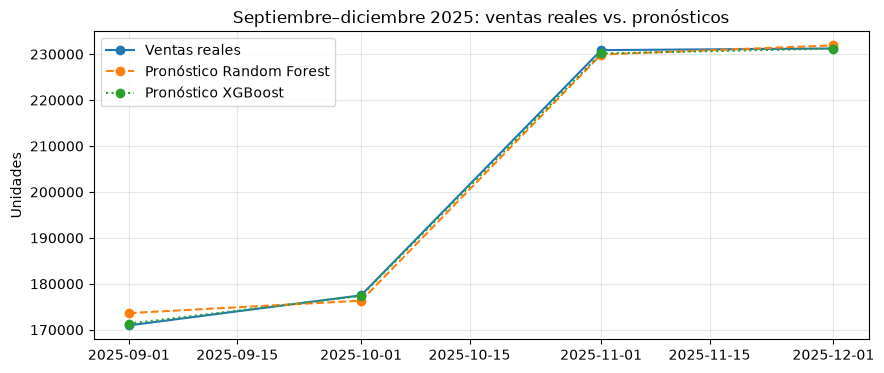

,units_sold,pronostico_rf,pronostico_xgb,units_expected
fecha,,,,
2025-09-01,170951,173630.0,171342.0,1156597
2025-10-01,177498,176332.0,177364.0,1145364
2025-11-01,230877,229923.0,230154.0,1150628
2025-12-01,231237,231907.0,231206.0,1151011


In [23]:
corte = '2025-09-01'
entrenamiento = datos['fecha'] < corte
prueba = datos['fecha'] >= corte

# Tomamos de los diccionarios los modelos elegidos en la validación y los entrenamos
mejor_rf = opciones_rf[mejor_hiper_rf]
mejor_rf.fit(X[entrenamiento], y[entrenamiento])

mejor_xgb = opciones_xgb[mejor_hiper_xgb]
mejor_xgb.fit(X[entrenamiento], y[entrenamiento])

# Guardamos los pronósticos en una tabla
resultado = datos.loc[prueba, ['fecha', 'region', 'units_sold', 'units_expected']].copy()
resultado['pronostico_rf'] = mejor_rf.predict(X[prueba])
resultado['pronostico_xgb'] = mejor_xgb.predict(X[prueba])

print('Resultado en la prueba (septiembre–diciembre 2025):')
print('Random Forest:', evaluar(resultado['units_sold'], resultado['pronostico_rf']))
print('XGBoost:      ', evaluar(resultado['units_sold'], resultado['pronostico_xgb']))

# Total por mes: ventas reales vs. pronósticos de los dos modelos
total_mes = resultado.groupby('fecha')[['units_sold', 'pronostico_rf', 'pronostico_xgb', 'units_expected']].sum()

plt.figure(figsize=(10, 4))
plt.plot(total_mes.index, total_mes['units_sold'], marker='o', label='Ventas reales')
plt.plot(total_mes.index, total_mes['pronostico_rf'], marker='o', linestyle='--', label='Pronóstico Random Forest')
plt.plot(total_mes.index, total_mes['pronostico_xgb'], marker='o', linestyle=':', label='Pronóstico XGBoost')
plt.title('Septiembre–diciembre 2025: ventas reales vs. pronósticos')
plt.ylabel('Unidades')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# El pronóstico actual no se grafica porque es ~6 veces mayor y aplastaría la escala
total_mes.round(0)

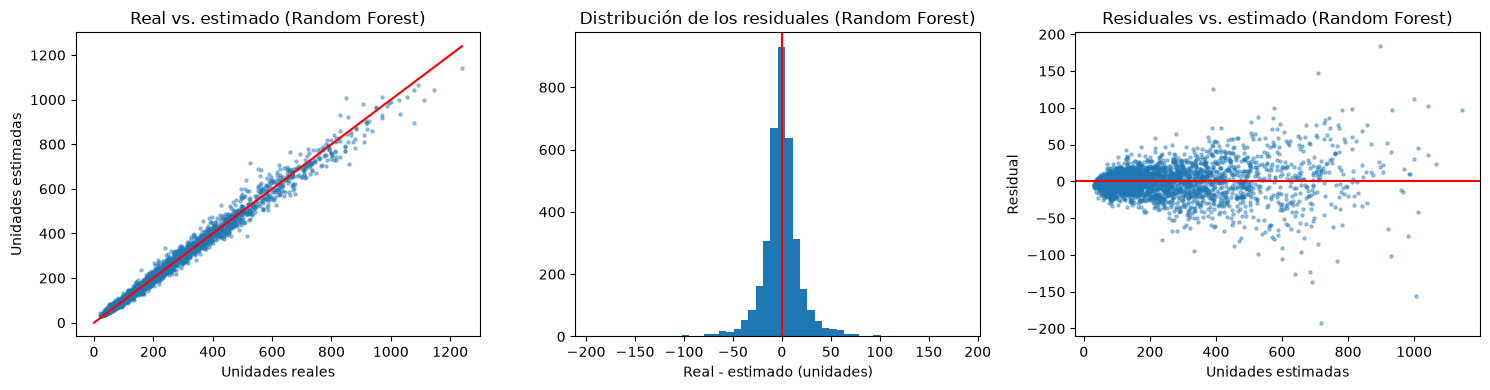

Random Forest -> residual promedio: -0.34 unidades
El 90% de los errores está entre -29.9 y 29.9 unidades


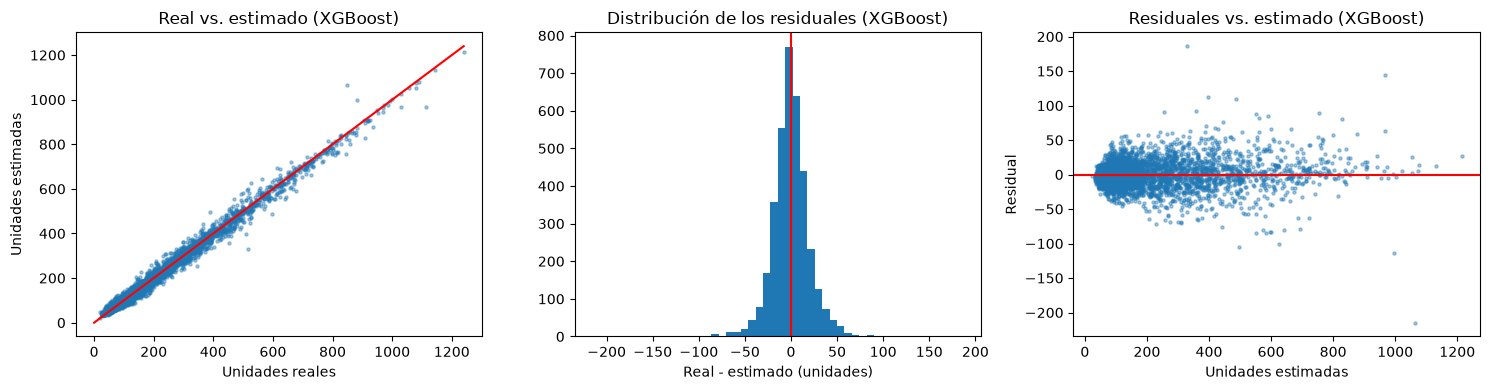

XGBoost -> residual promedio: 0.14 unidades
El 90% de los errores está entre -29.9 y 33.0 unidades


In [24]:
# Función que hace las 3 gráficas de errores de un modelo
def graficar_residuales(nombre, pronostico):
    residual = resultado['units_sold'] - pronostico      # error = real - estimado

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))

    # 1) Real vs. estimado: si el modelo fuera perfecto, todos los puntos caerían en la línea roja
    ax[0].scatter(resultado['units_sold'], pronostico, s=5, alpha=0.4)
    maximo = resultado['units_sold'].max()
    ax[0].plot([0, maximo], [0, maximo], color='red')
    ax[0].set_title('Real vs. estimado (' + nombre + ')')
    ax[0].set_xlabel('Unidades reales')
    ax[0].set_ylabel('Unidades estimadas')

    # 2) Distribución de los residuales: deberían estar centrados en 0
    ax[1].hist(residual, bins=50)
    ax[1].axvline(0, color='red')
    ax[1].set_title('Distribución de los residuales (' + nombre + ')')
    ax[1].set_xlabel('Real - estimado (unidades)')

    # 3) Residuales vs. estimado: no debería haber un patrón
    ax[2].scatter(pronostico, residual, s=5, alpha=0.4)
    ax[2].axhline(0, color='red')
    ax[2].set_title('Residuales vs. estimado (' + nombre + ')')
    ax[2].set_xlabel('Unidades estimadas')
    ax[2].set_ylabel('Residual')

    plt.tight_layout()
    plt.show()

    print(nombre, '-> residual promedio:', round(residual.mean(), 2), 'unidades')
    print('El 90% de los errores está entre', round(residual.quantile(0.05), 1), 'y', round(residual.quantile(0.95), 1), 'unidades')

graficar_residuales('Random Forest', resultado['pronostico_rf'])
graficar_residuales('XGBoost', resultado['pronostico_xgb'])

In [25]:
# Error de los dos modelos por región
resultado['error_rf'] = np.abs(resultado['units_sold'] - resultado['pronostico_rf'])
resultado['error_xgb'] = np.abs(resultado['units_sold'] - resultado['pronostico_xgb'])

sumas = resultado.groupby('region')[['units_sold', 'error_rf', 'error_xgb']].sum()
sumas['WAPE Random Forest (%)'] = (sumas['error_rf'] / sumas['units_sold'] * 100).round(2)
sumas['WAPE XGBoost (%)'] = (sumas['error_xgb'] / sumas['units_sold'] * 100).round(2)

sumas[['WAPE Random Forest (%)', 'WAPE XGBoost (%)']].sort_values('WAPE Random Forest (%)')

,WAPE Random Forest (%),WAPE XGBoost (%)
region,,
Ciudad de México,5.21,3.64
Zona Metropolitana de Monterrey,5.78,5.64
Zona Metropolitana de Guadalajara,5.83,7.08
Bajío,6.54,9.53
Noroeste,7.27,11.62
Sur,7.82,11.53
Sureste,8.15,12.73


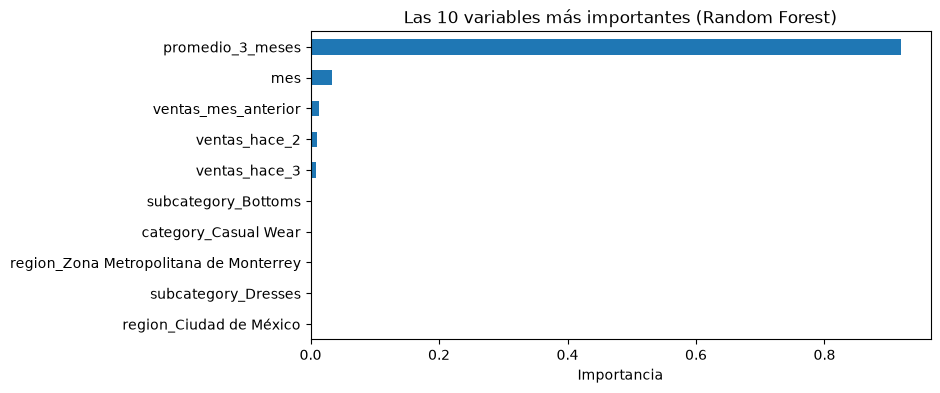

In [26]:
# ¿Qué variables usa más el modelo? (segundo método de selección de variables)
importancia = pd.Series(mejor_rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
importancia.sort_values().plot(kind='barh')
plt.title('Las 10 variables más importantes (Random Forest)')
plt.xlabel('Importancia')
plt.show()

## 12. Impacto del preprocesamiento
Para medir qué tanto ayudó la preparación de los datos, se entrenan los dos modelos (partición 80/20, mejores hiperparámetros) con **4 grupos de variables**:
1. **Básicas:** región, categoría, subcategoría y mes (codificadas con One-Hot).
2. **Básicas + precio** (el precio como identificador del producto).
3. **Básicas + ventas pasadas** (las variables creadas en el preprocesamiento): **modelo final**.
4. **Básicas + ventas pasadas + precio** (prueba de robustez: ¿cuánto aporta el precio?).

In [27]:
from sklearn.base import clone   # clone() hace una copia del modelo SIN entrenar (con los mismos hiperparámetros)

basicas = ['region', 'category', 'subcategory', 'mes']
rezagos = ['ventas_mes_anterior', 'ventas_hace_2', 'ventas_hace_3', 'promedio_3_meses']

grupos = {
    '1. Básicas': basicas,
    '2. Básicas + precio': basicas + ['static_price'],
    '3. Básicas + ventas pasadas (modelo final)': basicas + rezagos,
    '4. Básicas + ventas pasadas + precio': basicas + rezagos + ['static_price'],
}

comparacion = []
for nombre_modelo, modelo_elegido in [('Random Forest', mejor_rf), ('XGBoost', mejor_xgb)]:
    for nombre_grupo, columnas in grupos.items():
        X_grupo = pd.get_dummies(datos[columnas], columns=['region', 'category', 'subcategory'], dtype=int)

        modelo = clone(modelo_elegido)
        modelo.fit(X_grupo[entrenamiento], y[entrenamiento])

        fila = evaluar(y[prueba], modelo.predict(X_grupo[prueba]))
        fila['Modelo'] = nombre_modelo
        fila['Variables'] = nombre_grupo
        comparacion.append(fila)

pd.DataFrame(comparacion)[['Modelo', 'Variables', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

,Modelo,Variables,MAE,RMSE,WAPE (%),R2
0,Random Forest,1. Básicas,50.43,78.20,22.65,0.830
1,Random Forest,2. Básicas + precio,14.34,22.57,6.44,0.986
2,Random Forest,3. Básicas + ventas pasadas (modelo final),13.31,20.80,5.98,0.988
3,Random Forest,4. Básicas + ventas pasadas + precio,13.08,20.29,5.87,0.989
4,XGBoost,1. Básicas,50.36,78.16,22.62,0.830
5,XGBoost,2. Básicas + precio,15.63,21.89,7.02,0.987
6,XGBoost,3. Básicas + ventas pasadas (modelo final),14.64,20.54,6.58,0.988
7,XGBoost,4. Básicas + ventas pasadas + precio,13.23,18.73,5.94,0.990


**Interpretación:**
- Con solo las variables **básicas** el error es alto: el modelo sabe la región, la categoría y el mes, pero no cuánto vende cada producto.
- Con el **precio** el error baja mucho, pero no porque el precio explique las ventas: el modelo lo usa para **reconocer el producto** y "recordar" lo que vendió en 2024, que se repite en 2025.
- Con las **ventas pasadas** (creadas en el preprocesamiento) el error baja casi igual **sin identificar el producto**: el modelo aprende del nivel de ventas reciente de cada serie.
- **Prueba de robustez:** agregar el precio a las ventas pasadas casi no cambia el error. Es decir, el modelo final no depende del precio, y por eso se excluyó para reducir esa dependencia. Que esto lo haga más robusto ante cambios de precio es algo pendiente de validar, y el modelo **no sirve para productos nuevos**, porque necesita 3 meses de ventas previas.

## 13. Pronóstico de varios meses (recursivo)
Hasta aquí, para pronosticar cada mes de prueba el modelo usó las **ventas reales** del mes anterior (pronóstico a **un mes**). En la vida real, si DanuStore quiere planear septiembre–diciembre desde agosto, todavía no conoce las ventas de septiembre, octubre ni noviembre.

Por eso se hace un **pronóstico recursivo**: se pronostica septiembre; ese pronóstico se usa como "venta del mes anterior" para pronosticar octubre, y así sucesivamente. Los errores se van acumulando, así que este es el **error realista para planear varios meses**.

In [28]:
# Función que calcula las ventas pasadas (igual que en la sección 3), pero sobre la columna que le digamos
def calcular_rezagos(tabla, columna):
    grupo = tabla.groupby(['product_id', 'region'])[columna]
    tabla['ventas_mes_anterior'] = grupo.shift(1)
    tabla['ventas_hace_2'] = grupo.shift(2)
    tabla['ventas_hace_3'] = grupo.shift(3)
    tabla['promedio_3_meses'] = (tabla['ventas_mes_anterior'] + tabla['ventas_hace_2'] + tabla['ventas_hace_3']) / 3
    return tabla

meses_prueba = ['2025-09-01', '2025-10-01', '2025-11-01', '2025-12-01']
recursivo = []

for nombre_modelo, modelo in [('Random Forest', mejor_rf), ('XGBoost', mejor_xgb)]:

    # 1) Copiamos los datos y "borramos" las ventas desde septiembre 2025 (como si aún no las conociéramos)
    historia = df.copy()
    historia['ventas_simuladas'] = historia['units_sold']
    historia.loc[historia['fecha'] >= '2025-09-01', 'ventas_simuladas'] = np.nan

    # 2) Pronosticamos un mes a la vez y guardamos el pronóstico como si fuera la venta de ese mes
    for mes in meses_prueba:
        historia = calcular_rezagos(historia, 'ventas_simuladas')
        X_historia = pd.get_dummies(historia[variables], columns=['region', 'category', 'subcategory'], dtype=int)

        filas_del_mes = historia['fecha'] == mes
        historia.loc[filas_del_mes, 'ventas_simuladas'] = modelo.predict(X_historia[filas_del_mes])

    # 3) Comparamos los pronósticos contra las ventas reales, mes por mes
    numero_de_mes = 1
    for mes in meses_prueba:
        filas_del_mes = historia['fecha'] == mes
        fila = evaluar(historia.loc[filas_del_mes, 'units_sold'], historia.loc[filas_del_mes, 'ventas_simuladas'])
        fila['Modelo'] = nombre_modelo
        fila['Mes'] = mes[:7]
        fila['Meses adelante'] = numero_de_mes
        recursivo.append(fila)
        numero_de_mes = numero_de_mes + 1

    # 4) Y el bloque completo septiembre–diciembre
    filas_prueba = historia['fecha'] >= '2025-09-01'
    fila = evaluar(historia.loc[filas_prueba, 'units_sold'], historia.loc[filas_prueba, 'ventas_simuladas'])
    fila['Modelo'] = nombre_modelo
    fila['Mes'] = 'Bloque sep–dic'
    fila['Meses adelante'] = '1 a 4'
    recursivo.append(fila)

tabla_recursiva = pd.DataFrame(recursivo)[['Modelo', 'Mes', 'Meses adelante', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]
tabla_recursiva

,Modelo,Mes,Meses adelante,MAE,RMSE,WAPE (%),R2
0,Random Forest,2025-09,1,10.95,16.61,5.83,0.988
1,Random Forest,2025-10,2,18.38,27.97,9.42,0.971
2,Random Forest,2025-11,3,27.76,40.78,10.94,0.962
3,Random Forest,2025-12,4,31.15,47.01,12.26,0.951
4,Random Forest,Bloque sep–dic,1 a 4,22.06,35.11,9.91,0.966
5,XGBoost,2025-09,1,13.68,18.63,7.28,0.985
6,XGBoost,2025-10,2,18.57,26.01,9.52,0.975
7,XGBoost,2025-11,3,27.91,39.40,11.00,0.965
8,XGBoost,2025-12,4,30.57,45.18,12.03,0.955
9,XGBoost,Bloque sep–dic,1 a 4,22.68,33.97,10.19,0.968


In [29]:
# Comparación: error a un mes vs. error recursivo (septiembre–diciembre 2025)
bloque = tabla_recursiva[tabla_recursiva['Mes'] == 'Bloque sep–dic']

comparacion_horizonte = pd.DataFrame({
    'Modelo': ['Random Forest', 'XGBoost', 'Pronóstico actual (units_expected)'],
    'A un mes (ventas reales)': [evaluar(resultado['units_sold'], resultado['pronostico_rf'])['WAPE (%)'],
                                 evaluar(resultado['units_sold'], resultado['pronostico_xgb'])['WAPE (%)'],
                                 evaluar(resultado['units_sold'], resultado['units_expected'])['WAPE (%)']],
    'Recursivo (bloque sep–dic)': [bloque['WAPE (%)'].iloc[0],
                                   bloque['WAPE (%)'].iloc[1],
                                   evaluar(resultado['units_sold'], resultado['units_expected'])['WAPE (%)']],
})
print('WAPE (%) en septiembre–diciembre 2025:')
comparacion_horizonte

WAPE (%) en septiembre–diciembre 2025:


,Modelo,A un mes (ventas reales),Recursivo (bloque sep–dic)
0,Random Forest,5.98,9.91
1,XGBoost,6.58,10.19
2,Pronóstico actual (units_expected),467.95,467.95


**Interpretación:** al pronosticar varios meses con sus propios pronósticos, el error **crece mes a mes** porque los errores se acumulan. El error **del bloque completo** septiembre–diciembre es el que se compara en la tabla; el error **a cuatro meses de horizonte** (solo diciembre) es mayor, y aparece en la tabla anterior. Aun así, los dos son mucho menores que el error del pronóstico actual de DanuStore.

## 14. Conclusiones
**Resultados por partición (WAPE a un mes):**

| Partición | Ingenuo estacional (año anterior) | Random Forest | XGBoost | Ingenuo (mes anterior) | Pronóstico actual |
|---|---|---|---|---|---|
| 80/20 | 0.29 % | **5.98 %** | 6.58 % | 19.8 % | 468 % |
| 70/30 | 0.31 % | **6.07 %** | 6.97 % | 18.7 % | 471 % |
| 60/40 | 0.30 % | **6.12 %** | 7.05 % | 18.2 % | 483 % |

**¿Qué modelo y qué división funcionaron mejor?**
- **Entre los modelos de ML evaluados, el mejor es Random Forest** (100 árboles, sin límite de profundidad). Tiene el menor WAPE en las tres particiones, y la validación temporal (mayo–agosto 2025) confirmó las configuraciones identificadas en el análisis exploratorio. Como el periodo septiembre–diciembre ya había sido consultado, **falta una evaluación independiente con datos nuevos**. En septiembre–diciembre 2025 obtuvo un WAPE de 5.98 %, un MAE de 13.31 unidades y un R² de 0.988.
- **XGBoost** quedó cerca (6.58 %, mismo R² y RMSE ligeramente menor, 20.54 contra 20.80), pero su error es menos parejo entre regiones: Random Forest va de 5.2 % a 8.2 %, y XGBoost de 3.6 % a 12.7 %.
- **Particiones:** los resultados son muy parecidos en las tres (5.98 % a 6.12 % para Random Forest). Como los periodos de prueba son distintos y se enciman, **no se puede afirmar que una división sea mejor**; lo que muestran es que el modelo es **estable**, incluso entrenando con solo 13 meses.
- **Ambos modelos le ganan por mucho al pronóstico actual de DanuStore** (~470 %) y a repetir el mes pasado (~19 %).
- **El ingenuo estacional (repetir el mismo mes del año anterior) obtuvo el menor error entre los métodos evaluados (~0.3 %).** Esto se debe a que en esta base **las ventas de 2025 son casi una copia de las de 2024** (76.6 % de los registros son idénticos). Los modelos de ML se construyeron sin esa información como decisión experimental, para que dependan del nivel de ventas reciente, la región y la temporada; si eso los hace más útiles cuando las ventas no se repiten queda **pendiente de validar** con datos nuevos.
- **Pronóstico de varios meses:** si se pronostica septiembre–diciembre desde agosto, usando los propios pronósticos como entrada, el error de Random Forest sube mes a mes: 5.8 % a un mes (septiembre), 9.4 % a dos, 10.9 % a tres y **12.3 % a cuatro meses** (diciembre). Para el **bloque completo septiembre–diciembre** el error es de **9.9 %**.
- **Residuales:** en los dos modelos están centrados en 0 y el 90 % de los errores está entre −30 y +33 unidades, sin un patrón visible.

**¿Qué impacto tuvo el preprocesamiento?**
- **Crear las ventas pasadas** fue lo más importante. Con solo región, categoría, subcategoría y mes el error es de **22.6 %**; con las ventas pasadas baja a **6.0 %** en Random Forest y 6.6 % en XGBoost.
- **Excluir `static_price`:** como cada producto tiene un precio único, el precio funcionaba como identificador del producto. La prueba de robustez muestra que quitarlo casi no cambia el error (5.87 % con precio contra 5.98 % sin él), así que el modelo no depende de él. Se excluyó para reducir esa dependencia; su efecto ante cambios de precio queda pendiente de validar.
- **Excluir las variables con fuga** (Ventas_Acumuladas, Venta_Promedio_Diaria, Cumplimiento, etc.) evita un modelo "perfecto" pero inútil en la vida real.
- **El One-Hot Encoding** permitió usar región, categoría y subcategoría. **La normalización no fue necesaria** porque los modelos de árboles no dependen de la escala.

**¿Qué impacto tuvo el ajuste de hiperparámetros?**
Se compararon **configuraciones completas** (en cada una cambian varios hiperparámetros a la vez), así que no se puede atribuir la diferencia a un solo parámetro. Lo que sí se observa:
- **Random Forest:** las configuraciones con árboles más limitados (menor `max_depth`, mayor `min_samples_leaf`) tuvieron más error: 5.98 % sin límite, 7.44 % con `max_depth` = 15 y 12.10 % con `max_depth` = 8 (partición 80/20).
- **XGBoost:** la configuración con árboles poco profundos (`max_depth` = 4) tuvo 11.79 %, y la de 800 árboles, `learning_rate` = 0.03 y `max_depth` = 8 bajó a 6.58 %.
- En los dos casos, las configuraciones más flexibles funcionaron mejor, lo cual tiene sentido porque necesitan distinguir 910 combinaciones de producto y región.

**Beneficio para DanuStore:** con un pronóstico basado en las ventas reales recientes, la región y la temporada, puede planear su stock según lo que realmente se va a vender, en lugar de un pronóstico plano e inflado, y así reducir el sobreinventario (según el análisis de la investigación 5.1, hoy el stock alcanza para ~208 días de venta real en lugar de los ~34 planeados).

**Limitantes:**
1. **Las ventas de 2025 repiten casi exactamente las de 2024.** Por eso repetir el año anterior es casi perfecto y los errores de los modelos son **optimistas**. Hay que confirmar con DanuStore si estos datos son reales y validar el modelo con datos nuevos antes de usarlo.
2. Las ventas son solo de clientes registrados.
3. El error crece con el horizonte: ~6 % a un mes y ~12 % a cuatro meses (9.9 % para el bloque de cuatro meses). Lo recomendable es reentrenar y pronosticar cada mes con las ventas reales más recientes.
4. El modelo necesita **3 meses de ventas previas** de cada producto y región, así que no sirve para productos nuevos sin historial.
5. Los meses de prueba (septiembre–diciembre 2025) se consultaron durante el análisis exploratorio, así que el error reportado puede ser optimista; la validación confirmó la elección, pero se necesita una evaluación con datos nuevos.